In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

In [2]:
L = 5                                     # panjang lattice kubik
N = L * L * L                             # jumlah spin
J = 1.0                                   # kuat interaksi
kv = 0.001                                # anisotropy
B = 0.0                                   # medan eksternal

n_therm = 50
n_measure = 100

sigma_initial = 60.0
T = np.linspace(0.1, 2.2, 12)

In [3]:
def random_spin_field():
    spins = np.random.normal(size=(L, L, L, 3))
    spins /= np.linalg.norm(spins, axis=3, keepdims=True)
    return spins

lattice = random_spin_field()
print(lattice.shape)

(5, 5, 5, 3)


$$
\mathcal{H}
=
-J\sum_{\langle i,j\rangle}\mathbf{S}_i\cdot\mathbf{S}_j
-k_v\sum_i(S_i^z)^2
-B\sum_i S_i^z
\\
\Delta E
=
-J(\mathbf{S}_i'-\mathbf{S}_i)\cdot\mathbf{H}_i^{\mathrm{nn}}
-k_v\left[(S_i^{\prime z})^2-(S_i^z)^2\right]
-B\left(S_i^{\prime z}-S_i^z\right),

$$
dimana
$$
\space \mathbf{H}_i^{\mathrm{nn}} = \sum_{j\in\mathrm{nn}(i)}\mathbf{S}_j

$$



In [4]:
def delta_energy(lattice, x, y, z, trial_spin):
    L = lattice.shape[0]
    nn = lattice[(x + 1) % L, y, z] + lattice[(x - 1) % L, y, z] + lattice[x, (y + 1) % L, z] + lattice[x, (y - 1) % L, z] + lattice[x, y, (z + 1) % L] + lattice[x, y, (z - 1) % L]
    old_spin = lattice[x, y, z]
    E_exchange = -J * np.dot(trial_spin - old_spin, nn)
    E_anisotropy = -kv * (trial_spin[2]**2 - old_spin[2]**2)
    E_field = -B * (trial_spin[2] - old_spin[2])
    return E_exchange + E_anisotropy + E_field

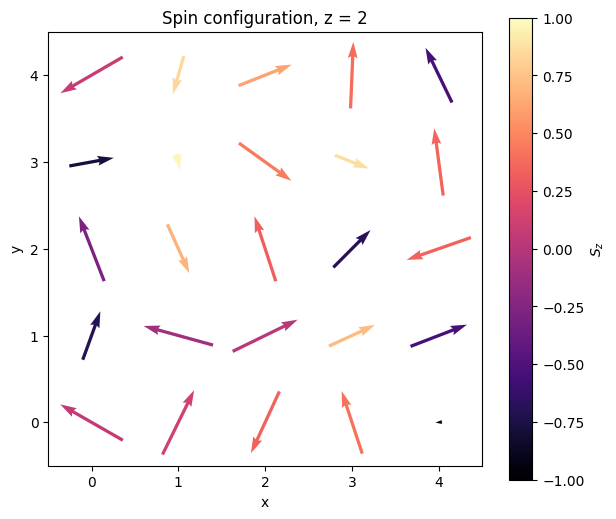

In [5]:

L = lattice.shape[0]

z_slice = L // 2

Sx = lattice[:, :, z_slice, 0].T
Sy = lattice[:, :, z_slice, 1].T
Sz = lattice[:, :, z_slice, 2].T

X, Y = np.meshgrid(np.arange(L), np.arange(L))
fig, ax = plt.subplots(figsize=(7, 6))
norm = Normalize(vmin=-1, vmax=1)
cmap = plt.get_cmap("magma")

q = ax.quiver(X, Y, Sx, Sy, Sz, cmap=cmap, norm=norm, pivot="middle", scale_units="xy", scale=1.2)

fig.colorbar(q, ax=ax, label=r"$S_z$")

ax.set_xlim(-0.5, L - 0.5)
ax.set_ylim(-0.5, L - 0.5)
ax.set_aspect("equal")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"Spin configuration, z = {z_slice}")

plt.show()

In [6]:
def magnetization(lattice):
    return np.sum(lattice, axis=(0, 1, 2))

$$
\mathbf{S}_i^{\mathrm{baru}}
=
\frac{
\mathbf{S}_i^{\mathrm{lama}}
+
\sigma\mathbf{\Gamma}
}{
\left|
\mathbf{S}_i^{\mathrm{lama}}
+
\sigma\mathbf{\Gamma}
\right|
}
$$

Jika jumlah trial move yang diterima adalah $N_{\mathrm{accepted}}$, maka acceptance rate adalah

$$
R
=
\frac{N_{\mathrm{accepted}}}{N}
$$

$$
f
=
\frac{0.5}{1-R}
$$

$$
\sigma_{\mathrm{baru}}
=
\sigma_{\mathrm{lama}}
\frac{0.5}{1-R}
$$


In [7]:
def gaussian_trial(spin, sigma):
    gamma = np.random.normal(size=3)
    trial = spin + sigma * gamma
    norm = np.linalg.norm(trial)

    if norm == 0.0:
        return spin.copy()

    return trial / norm

def metropolis_step(lattice, T, sigma):
    x = np.random.randint(0, L)
    y = np.random.randint(0, L)
    z = np.random.randint(0, L)

    trial_spin = gaussian_trial(lattice[x, y, z], sigma)
    dE = delta_energy(lattice, x, y, z, trial_spin)

    if dE <= 0 or np.random.random() < np.exp(-dE / T):
        lattice[x, y, z] = trial_spin
        return 1

    return 0

def update_sigma(sigma, R):
    if R >= 1.0:
        return 60.0

    sigma = sigma * (0.5 / (1.0 - R))
    sigma = min(sigma, 60.0)
    sigma = max(sigma, 1e-8)
    return sigma


In [8]:
def total_energy(lattice):
    E = 0.0

    for x in range(L):
        for y in range(L):
            for z in range(L):
                spin = lattice[x, y, z]
                xp = lattice[(x + 1) % L, y, z]
                yp = lattice[x, (y + 1) % L, z]
                zp = lattice[x, y, (z + 1) % L]
                E += -J * np.dot(spin, xp + yp + zp) - kv * spin[2]**2 - B * spin[2]

    return E

In [9]:
def simulate(lattice, temp):
    energies = []
    magnetizations = []
    R_history = []
    sigma_history = []

    sigma = sigma_initial

    for sweep in range(n_therm + n_measure):
        accepted = 0

        for i in range(N):
            accepted += metropolis_step(lattice, temp, sigma)

        R = accepted / N
        sigma = update_sigma(sigma, R)

        R_history.append(R)
        sigma_history.append(sigma)

        if sweep >= n_therm:
            energies.append(total_energy(lattice))
            magnetizations.append(magnetization(lattice))

    return (
        np.array(energies),
        np.array(magnetizations),
        np.array(R_history),
        np.array(sigma_history),
    )

In [10]:
def simulate_temp(lattice, T):
    c_vs_t = []
    kai_vs_t = []
    m_vs_t = []
    e_vs_t = []
    r_vs_t = []
    sigma_vs_t = []

    for index, t in enumerate(T):
        spins_t = lattice.copy()

        energies, magnetizations, R_history, sigma_history = simulate(spins_t, t)

        E_mean = np.mean(energies)
        E_2_mean = np.mean(energies ** 2)

        M_abs = np.linalg.norm(magnetizations, axis=1)
        M_abs_mean = np.mean(M_abs)
        M_2_mean = np.mean(M_abs ** 2)

        c = (E_2_mean - E_mean ** 2) / (N * t ** 2)
        Kai = (M_2_mean - M_abs_mean ** 2) / (N * t)

        c_vs_t.append(c)
        kai_vs_t.append(Kai)
        m_vs_t.append(M_abs_mean / N)
        e_vs_t.append(E_mean / N)
        r_vs_t.append(np.mean(R_history[n_therm:]))
        sigma_vs_t.append(np.mean(sigma_history[n_therm:]))

    return (
        np.array(c_vs_t),
        np.array(kai_vs_t),
        np.array(m_vs_t),
        np.array(e_vs_t),
        np.array(r_vs_t),
        np.array(sigma_vs_t),
    )


c_vs_t, kai_vs_t, m_vs_t, e_vs_t, r_vs_t, sigma_vs_t = simulate_temp(lattice, T)

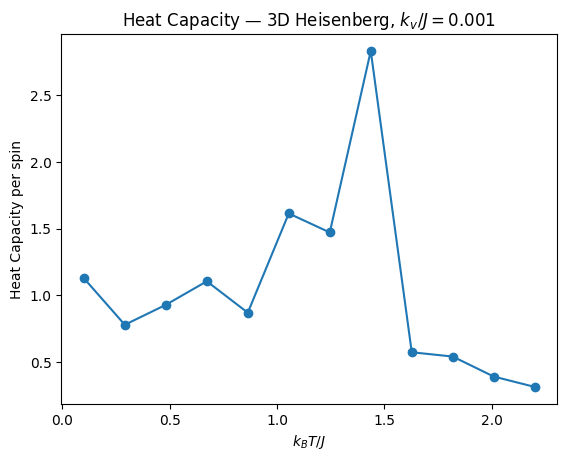

In [11]:
plt.plot(T, c_vs_t, marker="o")
plt.xlabel(r"$k_B T/J$")
plt.ylabel("Heat Capacity per spin")
plt.title(r"Heat Capacity — 3D Heisenberg, $k_v/J=0.001$")
plt.show()

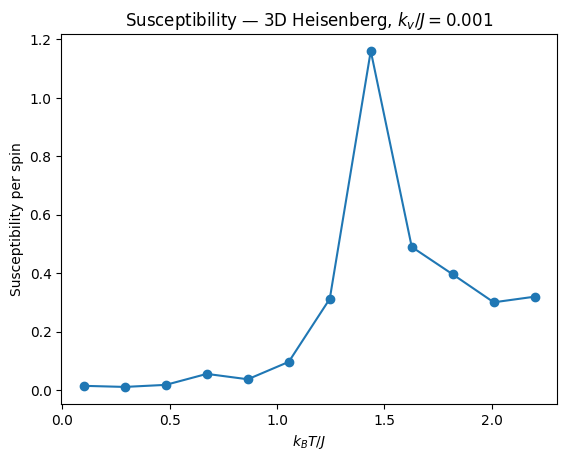

In [12]:
plt.plot(T, kai_vs_t, marker="o")
plt.xlabel(r"$k_B T/J$")
plt.ylabel("Susceptibility per spin")
plt.title(r"Susceptibility — 3D Heisenberg, $k_v/J=0.001$")
plt.show()

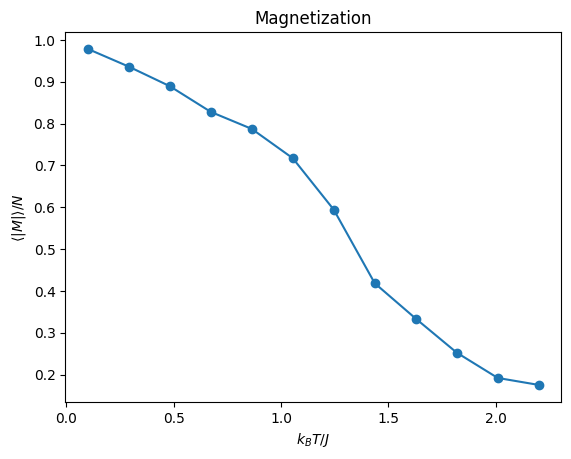

In [13]:
plt.plot(T, m_vs_t, marker="o")
plt.xlabel(r"$k_B T/J$")
plt.ylabel(r"$\langle |M| \rangle/N$")
plt.title("Magnetization")
plt.show()


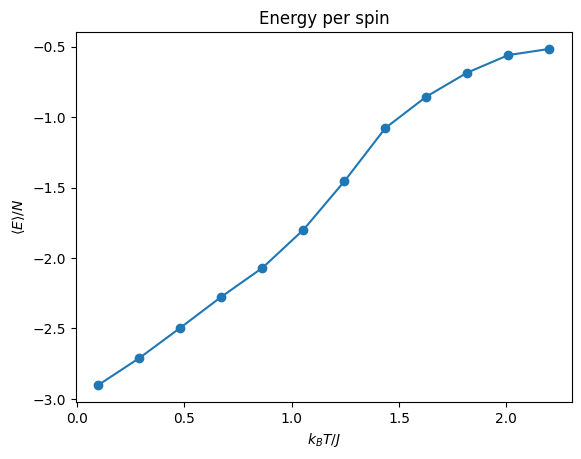

In [14]:
plt.plot(T, e_vs_t, marker="o")
plt.xlabel(r"$k_B T/J$")
plt.ylabel(r"$\langle E \rangle/N$")
plt.title("Energy per spin")
plt.show()


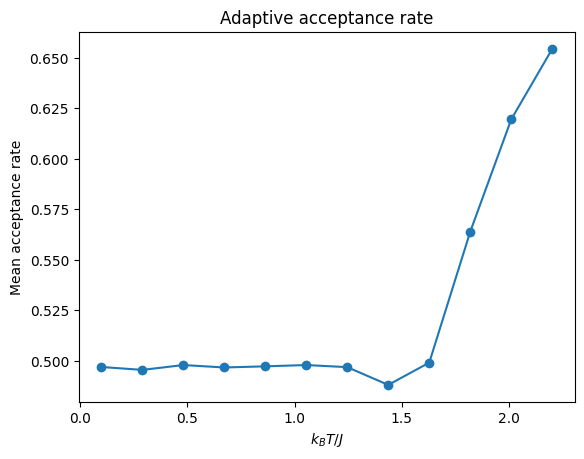

In [15]:
plt.plot(T, r_vs_t, marker="o")
plt.xlabel(r"$k_B T/J$")
plt.ylabel("Mean acceptance rate")
plt.title("Adaptive acceptance rate")
plt.show()


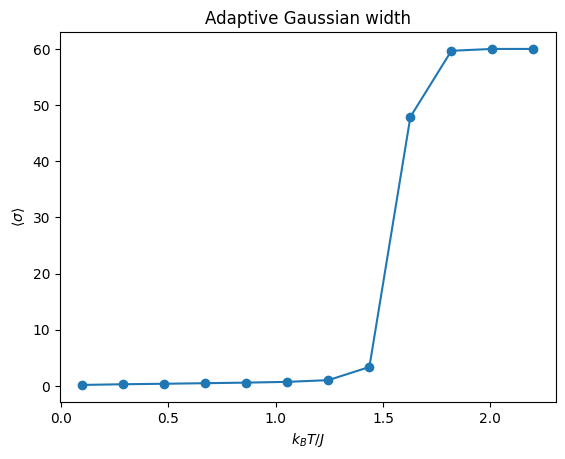

In [16]:
plt.plot(T, sigma_vs_t, marker="o")
plt.xlabel(r"$k_B T/J$")
plt.ylabel(r"$\langle \sigma \rangle$")
plt.title("Adaptive Gaussian width")
plt.show()

Simulating at T=2.20


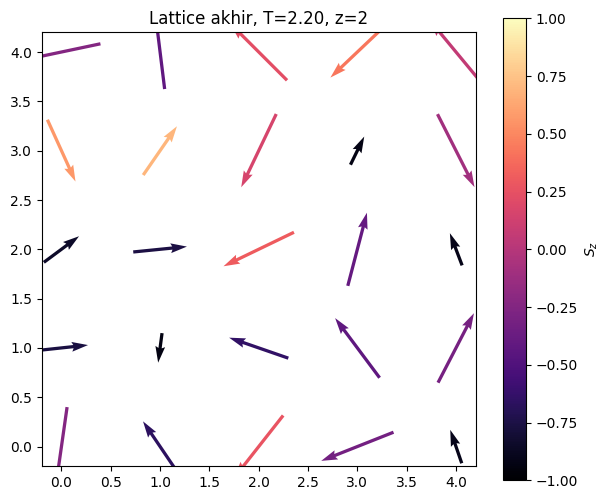

Simulating at T=2.01


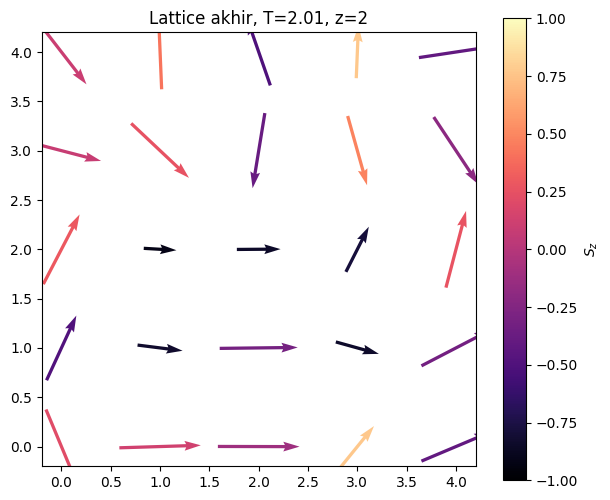

Simulating at T=1.82


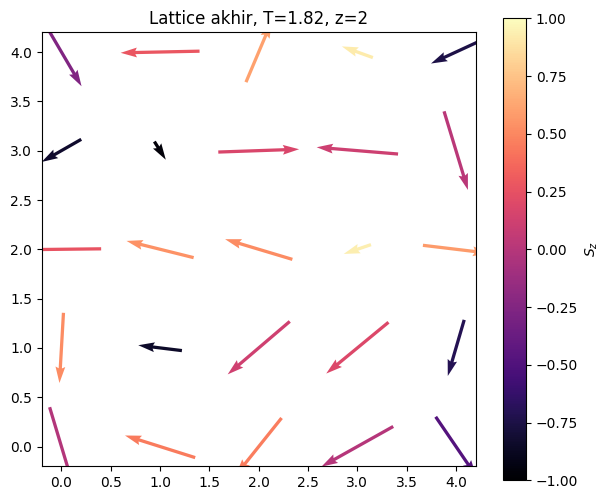

Simulating at T=1.63


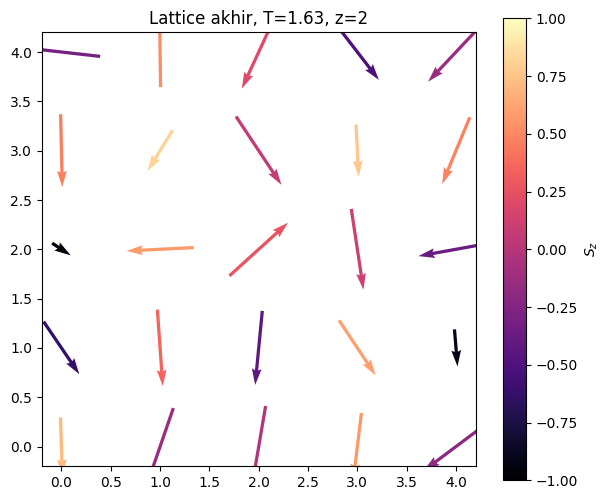

Simulating at T=1.44


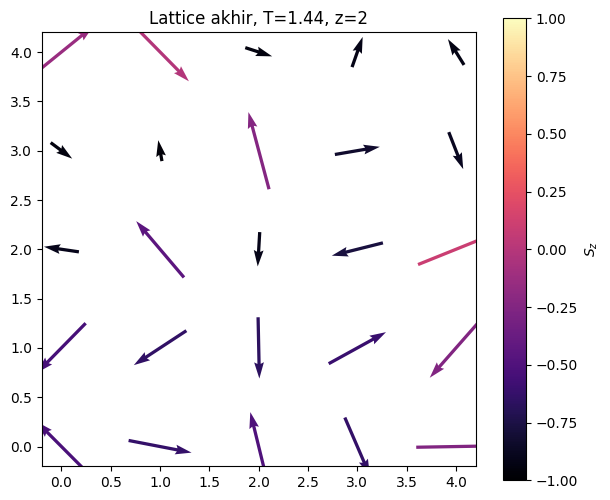

Simulating at T=1.25


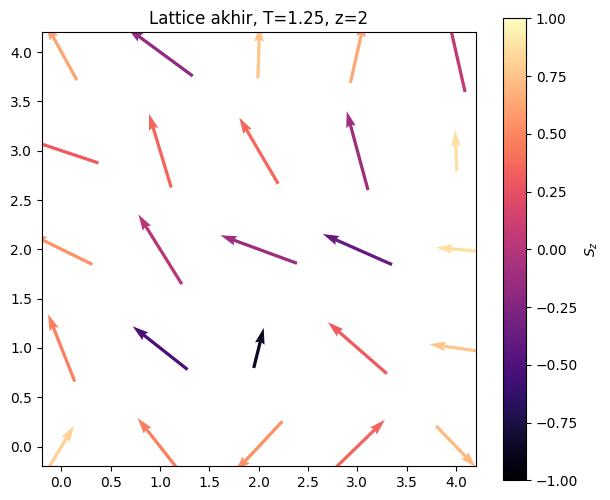

Simulating at T=1.05


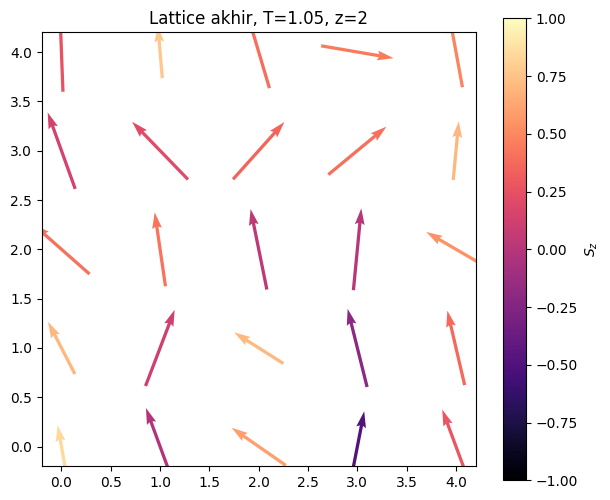

Simulating at T=0.86


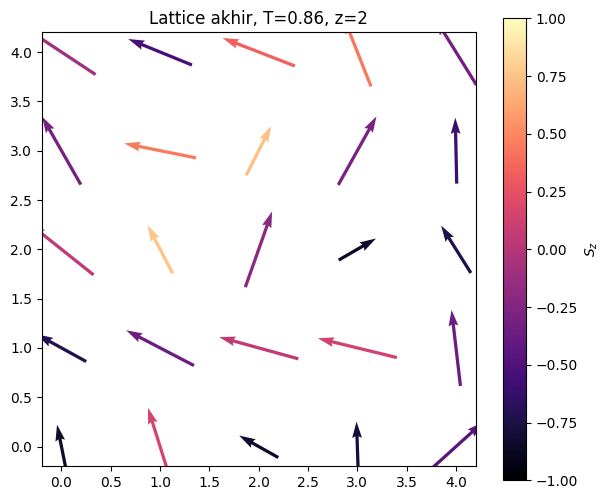

Simulating at T=0.67


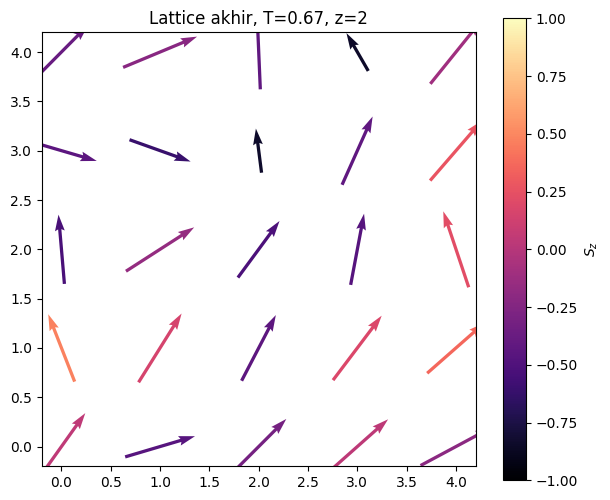

Simulating at T=0.48


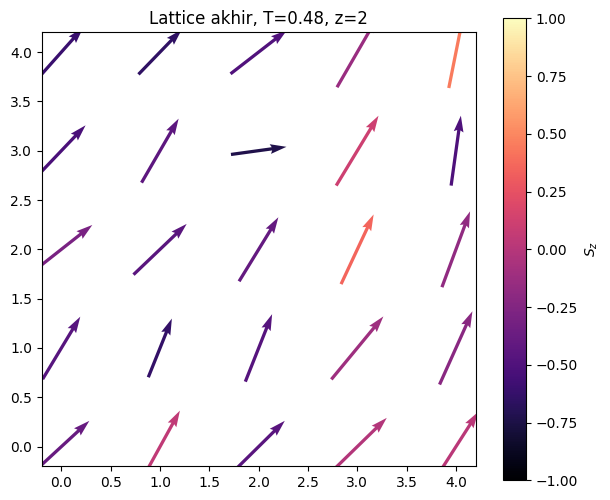

Simulating at T=0.29


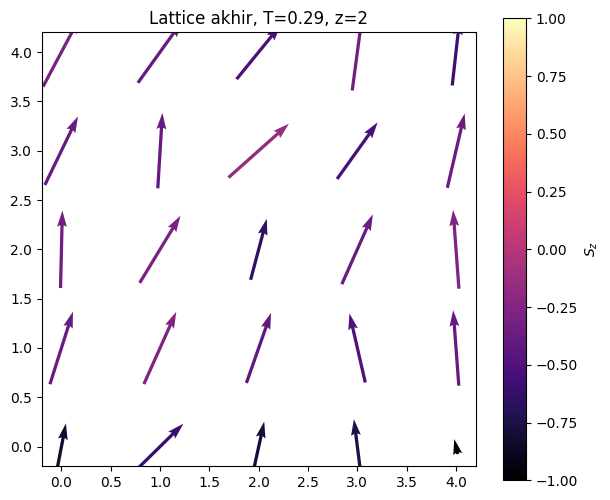

Simulating at T=0.10


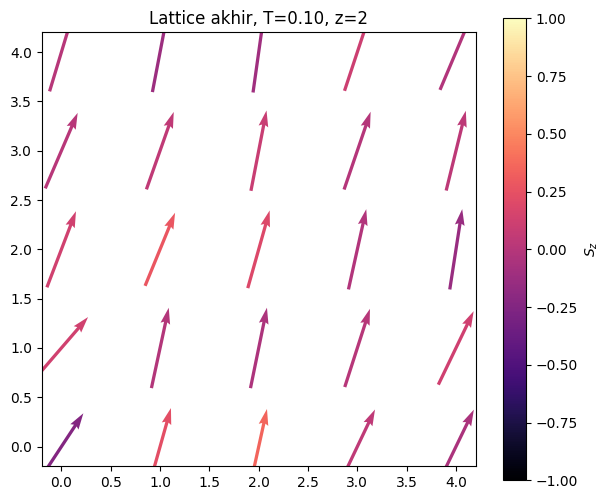

In [19]:
for i in reversed(T):
    print(f"Simulating at T={i:.2f}")
    temp = i
    final_lattice = lattice.copy()
    simulate(final_lattice, temp)

    z_slice = L // 2
    spins = final_lattice[:, :, z_slice, :]

    fig, ax = plt.subplots(figsize=(7, 6))
    q = ax.quiver(
        spins[:, :, 0].T,
        spins[:, :, 1].T,
        spins[:, :, 2].T,
        cmap="magma",
        norm=Normalize(vmin=-1, vmax=1),
        pivot="middle",
        scale_units="xy",
        scale=1.2,
    )
    fig.colorbar(q, ax=ax, label=r"$S_z$")
    ax.set_aspect("equal")
    ax.set_title(f"Lattice akhir, T={temp:.2f}, z={z_slice}")
    plt.show()